In [3]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import logging

In [4]:
logging.basicConfig(level=logging.INFO)

logger = logging.getLogger(__name__)
from src.IO.video import load_vid

DEFAULT_VIDEO_NAME="group_1_phase2_pan_outdoor.mp4"
frames = load_vid(DEFAULT_VIDEO_NAME, selected_frames=range(0, 180, 20))
len(frames)

INFO:src.IO.video:FPS: 30.00563379877105


9

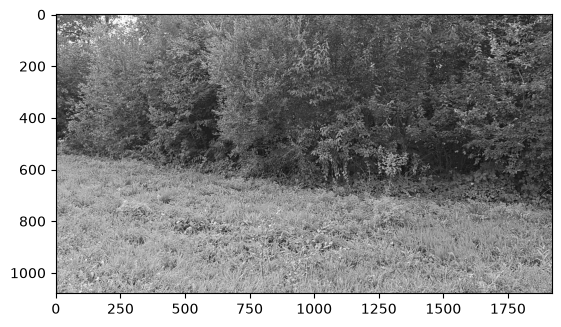

In [5]:
frame = frames[0]
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
plt.imshow(gray, cmap='gray')

In [6]:
detector = cv2.SIFT_create(nfeatures=100) # nfeatures: maximum number of features to retain 
keypoints = detector.detect(gray, None)

In [35]:
points = np.array([keypoint.pt for keypoint in keypoints])

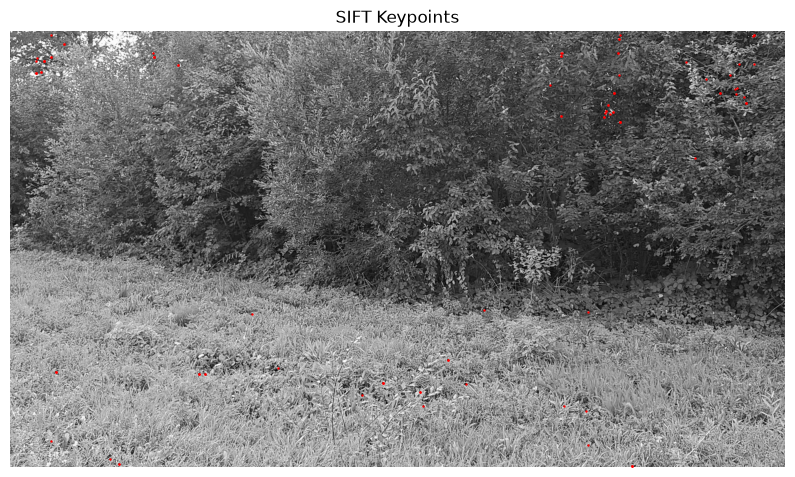

In [36]:
plt.figure(figsize=(10, 6))
plt.imshow(gray, cmap='gray')
plt.scatter(points[:, 0], points[:, 1], s=0.5, c='r')
plt.title('SIFT Keypoints')
plt.axis('off')
plt.show()

In [10]:
g1 = cv2.cvtColor(frames[0], cv2.COLOR_BGR2GRAY)
g2 = cv2.cvtColor(frames[1], cv2.COLOR_BGR2GRAY)
kp1, des1 = detector.detectAndCompute(g1, None)
kp2, des2 = detector.detectAndCompute(g2, None)

matcher = cv2.BFMatcher(cv2.NORM_L2)
knn = matcher.knnMatch(des1, des2, k=2) # 1 point in image 1, 2 points in image 2

In [39]:
knn[0][0]

< cv2.DMatch 0000029765A091D0>

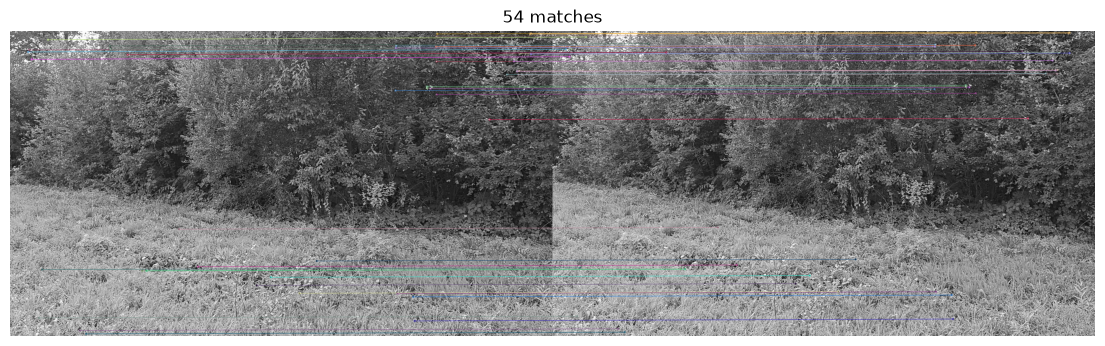

In [ ]:
similarity_threshold = 0.75
good = [p[0] for p in knn if len(p) == 2 and p[0].distance < similarity_threshold * p[1].distance]

vis = cv2.drawMatches(
    g1, kp1, g2, kp2, good, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(14, 5))
plt.imshow(vis)
plt.title(f"{len(good)} matches")
plt.axis("off")
plt.show()

In [40]:
for ratio in np.arange(0.5, 1.0, 0.05):
    good = [p[0] for p in knn if len(p) == 2 and p[0].distance < ratio * p[1].distance]
    if len(good) < 4:                      # a homography needs at least 4 point pairs
        logger.info("ratio %.2f: only %d matches", ratio, len(good)); continue

    pts1 = np.float32([kp1[m.queryIdx].pt for m in good])
    pts2 = np.float32([kp2[m.trainIdx].pt for m in good])
    H, mask = cv2.findHomography(pts2, pts1, cv2.RANSAC, 5.0)
    inl = mask.ravel().astype(bool)

    proj = cv2.perspectiveTransform(pts2[inl].reshape(-1, 1, 2), H).reshape(-1, 2)
    err = np.linalg.norm(proj - pts1[inl], axis=1).mean()   # reprojection error, in pixels
    logger.info("ratio %.2f: %3d matches, %3d inliers (%.0f%%), error %.2f px",
                ratio, len(good), inl.sum(), 100 * inl.mean(), err)

INFO:__main__:ratio 0.50:  44 matches,  44 inliers (100%), error 0.15 px
INFO:__main__:ratio 0.55:  48 matches,  48 inliers (100%), error 0.16 px
INFO:__main__:ratio 0.60:  50 matches,  50 inliers (100%), error 0.16 px
INFO:__main__:ratio 0.65:  52 matches,  52 inliers (100%), error 0.15 px
INFO:__main__:ratio 0.70:  52 matches,  52 inliers (100%), error 0.15 px
INFO:__main__:ratio 0.75:  54 matches,  54 inliers (100%), error 0.16 px
INFO:__main__:ratio 0.80:  56 matches,  54 inliers (96%), error 0.16 px
INFO:__main__:ratio 0.85:  60 matches,  56 inliers (93%), error 0.16 px
INFO:__main__:ratio 0.90:  66 matches,  59 inliers (89%), error 0.16 px
INFO:__main__:ratio 0.95:  75 matches,  60 inliers (80%), error 0.16 px


A homography is the transformation that maps points of one image onto another image of the same scene. It's a 3×3 matrix H acting on homogeneous coordinates, the "projective" level of the 2D transformation hierarchy from Part 3:

$$\lambda \begin{pmatrix} x' \\ y' \\ 1 \end{pmatrix} = \underbrace{\begin{pmatrix} h_{11} & h_{12} & h_{13} \\ h_{21} & h_{22} & h_{23} \\ h_{31} & h_{32} & h_{33} \end{pmatrix}}_{H} \begin{pmatrix} x \\ y \\ 1 \end{pmatrix} \quad\Rightarrow\quad x' = \frac{h_{11}x + h_{12}y + h_{13}}{h_{31}x + h_{32}y + h_{33}},\;\; y' = \frac{h_{21}x + h_{22}y + h_{23}}{h_{31}x + h_{32}y + h_{33}}$$

- **8 degrees of freedom.** H has 9 entries, but multiplying it by any constant gives the same mapping, because the division by λ cancels it. Each point match gives 2 equations, so you need at least 4 matches. That's why the code checks `len(good) < 4`.
- **What it can do.** It contains every simpler transformation: translation (only $h_{13}, h_{23}$), rotation, scaling, shear (affine), plus perspective effects through $h_{31}, h_{32}$, which turn rectangles into trapezoids. It maps straight lines to straight lines.
- **When it's exact.** When the camera only rotates about its optical center, or when the scene is flat (a wall, a document). That's why panoramas should be shot by rotating, not walking: translation produces parallax, which no single H can represent.

In your stitching code, `cv2.findHomography` estimates H from the matched points, and `cv2.warpPerspective` applies it to every pixel of the image to place it on the other image.